# Milestone 1: Data Profiling and Quality Audit with DuckDB
## Data Engineering Lifecycle - BTS Airline Flight Delays Dataset

### 1. Environment preparation

In [1]:
# dependencies / routing preparation

import sys
from pathlib import Path

ROOT_DIR = Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import duckdb
import polars as pl
import pyarrow as pa
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import BTS_CSV_PATH, RAW_DATA_DIR
from src.profiling import get_duckdb_connection, get_schema_description, profile_bts_flight_delays

print(f"DuckDB version: {duckdb.__version__}")
print(f"Polars version: {pl.__version__}")
print(f"PyArrow version: {pa.__version__}")
print(f"Raw dataset path: {BTS_CSV_PATH}")

DuckDB version: 1.5.6
Polars version: 2.0.0
PyArrow version: 26.0.0
Raw dataset path: /home/dewaszmi/studia/big-data-exercise-2026/data/raw/Airline_Delay_Cause.csv


### 2. Schema Discovery (Zero Full-Load)
Using DuckDB to inspect the file schema using `DESCRIBE SELECT * FROM '<file>'` without materializing the dataset into RAM.

In [2]:
# check if duckdb connection is working
con = get_duckdb_connection()
schema_df = get_schema_description(str(BTS_CSV_PATH), con=con)
schema_df

column_name,column_type,null,key,default,extra
str,str,str,str,str,str
"""year""","""BIGINT""","""YES""",null,null,null
"""month""","""BIGINT""","""YES""",null,null,null
"""carrier""","""VARCHAR""","""YES""",null,null,null
"""carrier_name""","""VARCHAR""","""YES""",null,null,null
"""airport""","""VARCHAR""","""YES""",null,null,null
…,…,…,…,…,…
"""carrier_delay""","""BIGINT""","""YES""",null,null,null
"""weather_delay""","""BIGINT""","""YES""",null,null,null
"""nas_delay""","""BIGINT""","""YES""",null,null,null


### 3. Comprehensive Data Profiling with DuckDB SQL
Here we execute an analytical aggregation query to measure:
* Total records and completeness per column (NULL counts).
* Min, max, and average values across all numeric indicators.
* Data coverage timeline (years, months, airlines, airports).

In [8]:
# use the profiling function to inspect completeness and possible null values
profiles = profile_bts_flight_delays(str(BTS_CSV_PATH), con=con)

print("Completeness and null audit:")
display(profiles["null_profile"])

print("\nSummarized statistics:")
display(
    profiles["descriptive_stats"].transpose(
        include_header=True, header_name="metric", column_names=["value"]
    )
)

Completeness and null audit:


metric,value
str,i64
"""total_rows""",398233
"""null_year""",0
"""null_month""",0
"""null_carrier""",0
"""null_carrier_name""",0
…,…
"""null_arr_del15""",950
"""null_carrier_ct""",657
"""null_arr_cancelled""",657



Summarized statistics:


metric,value
str,f64
"""min_year""",2003.0
"""max_year""",2025.0
"""min_month""",1.0
"""max_month""",12.0
"""min_arr_flights""",1.0
…,…
"""min_arr_cancelled""",0.0
"""max_arr_cancelled""",4951.0
"""min_arr_delay""",0.0


### 4. Technical and Domain Anomaly Detection
We audit the dataset for mathematical invariants and known domain characteristics:
1. **Component sum mismatch:** Does `arr_delay == carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay`?
2. **Fractional flight counts:** Why are columns like `carrier_ct` floating-point numbers instead of integers?
3. **100% cancellation periods:** Months where scheduled operations collapsed completely.

In [9]:
print("Detected anomalies and integrity checks:")
display(profiles["anomalies"])

# find rows where cumulative delay doesn't match the sum of individual delays
mismatch_query = f"""
SELECT year, month, carrier, airport, arr_flights, arr_del15, arr_delay,
       (carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay) AS calculated_sum,
       arr_delay - (carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay) AS delay_difference
FROM '{BTS_CSV_PATH}'
WHERE ABS(arr_delay - (carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay)) > 1
"""

df_mismatches = con.execute(mismatch_query).pl()
print(f"\nTotal mismatch instances: {df_mismatches.height}")
display(df_mismatches.head(10))

Detected anomalies and integrity checks:


anomaly_type,detected_count
str,i64
"""zero_or_negative_flights""",0
"""delayed_exceeds_total_flights""",0
"""cancelled_exceeds_total_flight…",0
"""negative_delay_minutes""",0
"""delay_components_sum_mismatch""",9
"""fractional_carrier_counts""",327994
"""all_flights_cancelled_records""",270



Total mismatch instances: 9


year,month,carrier,airport,arr_flights,arr_del15,arr_delay,calculated_sum,delay_difference
i64,i64,str,str,i64,i64,i64,i64,i64
2024,7,"""F9""","""MCO""",1274,393,39334,39154,180
2024,7,"""F9""","""MIA""",372,136,12812,12686,126
2024,1,"""C5""","""BRO""",101,21,2773,1428,1345
2023,11,"""F9""","""CLE""",492,99,6934,6880,54
2023,10,"""UA""","""DCA""",538,56,3006,2775,231
2022,1,"""ZW""","""AVP""",64,17,1313,1077,236
2021,3,"""F9""","""STL""",87,17,559,539,20
2020,8,"""DL""","""SEA""",1842,127,7690,7181,509
2017,8,"""F9""","""TTN""",187,44,4044,3850,194


### Domain Interpretation of Anomalies
* **Fractional Counts (`carrier_ct`, `weather_ct`, etc.):** When a single flight delay is attributed to multiple causes (e.g. bad weather cascading into late turnaround equipment), the US Department of Transportation allocates proportional weights (e.g. 0.5 to weather, 0.5 to late aircraft). Thus, counts are non-integers by regulatory design.
* **Component Sum Discrepancy:** The 9 records with discrepancies reflect retroactive reporting corrections or non-standard delay classifications in specific carrier reporting systems.
* **NULL Values (657 rows):** 657 monthly records contain NULL values for delay categories. These correspond to months where flights were scheduled but no actual operations took place or data submission was incomplete.

### 5. Analytical Aggregations and Visual Insights
Deep-dive OLAP queries to visualize delay distributions by airline, airport, and historical trends.

In [10]:
top_airports_query = f"""
SELECT 
    airport,
    airport_name,
    SUM(arr_flights) AS total_flights,
    SUM(arr_del15) AS total_delayed_flights,
    ROUND(SUM(arr_del15) * 100.0 / NULLIF(SUM(arr_flights), 0), 2) AS percentage_of_delayed_flights,
    ROUND(SUM(arr_delay) / 60.0 / 1000.0, 1) AS total_delay_thousands_of_hours
FROM '{BTS_CSV_PATH}'
WHERE arr_flights > 0
GROUP BY airport, airport_name
HAVING SUM(arr_flights) > 1000000
ORDER BY percentage_of_delayed_flights DESC
LIMIT 10
"""
df_top_airports = con.execute(top_airports_query).pl()
display(df_top_airports)

airport,airport_name,total_flights,total_delayed_flights,percentage_of_delayed_flights,total_delay_thousands_of_hours
str,str,"decimal[38,0]","decimal[38,0]",f64,f64
"""EWR""","""Newark, NJ: Newark Liberty Int…",2848697,776477,27.26,931.1
"""SFO""","""San Francisco, CA: San Francis…",3146031,768136,24.42,828.1
"""LGA""","""New York, NY: LaGuardia""",2613232,625661,23.94,688.2
"""JFK""","""New York, NY: John F. Kennedy …",2321380,532103,22.92,609.2
"""FLL""","""Fort Lauderdale, FL: Fort Laud…",1637828,360394,22.0,355.7
"""BOS""","""Boston, MA: Logan Internationa…",2633735,567662,21.55,604.4
"""ORD""","""Chicago, IL: Chicago O'Hare In…",6938498,1486102,21.42,1781.3
"""PHL""","""Philadelphia, PA: Philadelphia…",2191500,462947,21.12,493.5
"""MCO""","""Orlando, FL: Orlando Internati…",2746124,561299,20.44,564.4


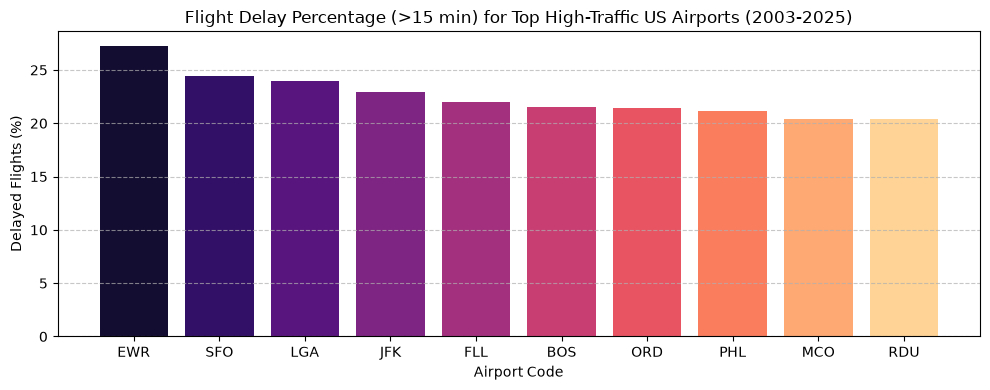

In [6]:
plt.figure(figsize=(10, 4))
plt.bar(
    df_top_airports["airport"].to_list(),
    df_top_airports["delay_percentage"].to_list(),
    color=sns.color_palette("magma", n_colors=df_top_airports.height),
)
plt.title("Flight Delay Percentage (>15 min) for Top High-Traffic US Airports (2003-2025)")
plt.ylabel("Delayed Flights (%)")
plt.xlabel("Airport Code")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

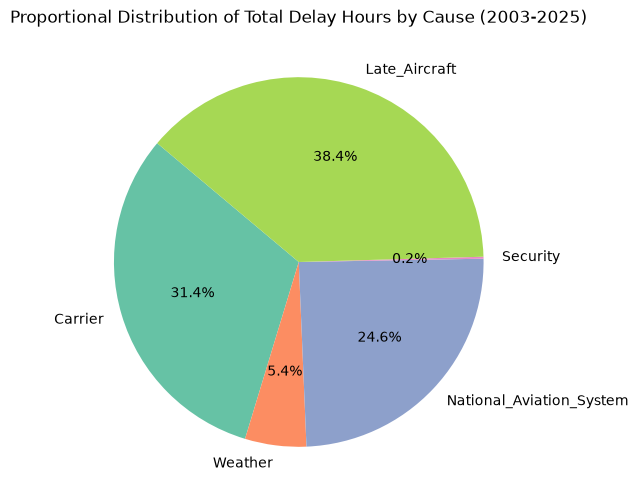

In [7]:
causes_query = f"""
SELECT
    ROUND(SUM(carrier_delay) / 60.0 / 1000.0, 1) AS Carrier,
    ROUND(SUM(weather_delay) / 60.0 / 1000.0, 1) AS Weather,
    ROUND(SUM(nas_delay) / 60.0 / 1000.0, 1) AS National_Aviation_System,
    ROUND(SUM(security_delay) / 60.0 / 1000.0, 1) AS Security,
    ROUND(SUM(late_aircraft_delay) / 60.0 / 1000.0, 1) AS Late_Aircraft
FROM '{BTS_CSV_PATH}'
"""
df_causes = con.execute(causes_query).pl()
cause_labels = df_causes.columns
cause_values = list(df_causes.row(0))

plt.figure(figsize=(6, 6))
plt.pie(
    cause_values,
    labels=cause_labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=sns.color_palette("Set2"),
)
plt.title("Proportional Distribution of Total Delay Hours by Cause (2003-2025)")
plt.show()